# Exercise 1

# 1.1

In [1]:
import autograd.numpy as np

In [2]:
# data input
csvname = 'breast_cancer_data.csv'
data1 = np.loadtxt(csvname,delimiter = ',')

# get input and output of dataset
x = data1[:-1,:]
y = data1[-1:,:] 

In [3]:
# compute linear combination of input points
def model(x,w):
    a = w[0] + np.dot(x.T,w[1:])
    return a.T

# an implementation of the softmax cost
def softmax(w):    
    cost = np.sum(np.log(1 + np.exp(-y*model(x,w))))
    return cost/float(np.size(y))

# an implementation of the perceptron cost
def perceptron(w):
    cost = np.sum(np.maximum(0, -y*model(x, w)))
    return cost/float(np.size(y))
    

# 1.2

In [4]:
# import automatic differentiator to compute gradient module
from autograd import grad 

# gradient descent function - inputs: g (input function), alpha (steplength parameter), max_its (maximum number of iterations), w (initialization)
def gradient_descent(g,alpha,max_its,w):
    # compute gradient module using autograd
    gradient = grad(g)

    # run the gradient descent loop
    weight_history = [w]           # container for weight history
    cost_history = [g(w)]          # container for corresponding cost function history
    for k in range(max_its):
        # evaluate the gradient, store current weights and cost function value
        grad_eval = gradient(w)

        # take gradient descent step
        w = w - alpha*grad_eval
        
        # record weight and cost
        weight_history.append(w)
        cost_history.append(g(w))
    return weight_history, cost_history

In [5]:
# parameters for gradient descent
max_its = 1000
w = 0.1*np.random.randn(9,1)
alpha_percep = 0.1
weight_history_percep, cost_history_percep = gradient_descent(perceptron,alpha_percep,max_its,w)
alpha_softmax = 1
weight_history_softmax, cost_history_softmax = gradient_descent(softmax,alpha_softmax,max_its,w)

# 1.3

In [6]:
### miscounts ###
def miscount(w, x, y):
    preds = model(x, w)
    return np.sum(-y*preds<0)

In [7]:
weight_history, _ =  gradient_descent(perceptron,alpha_percep,max_its,w)
miscount_history = [miscount(v,x,y) for v in weight_history]

# 1.4

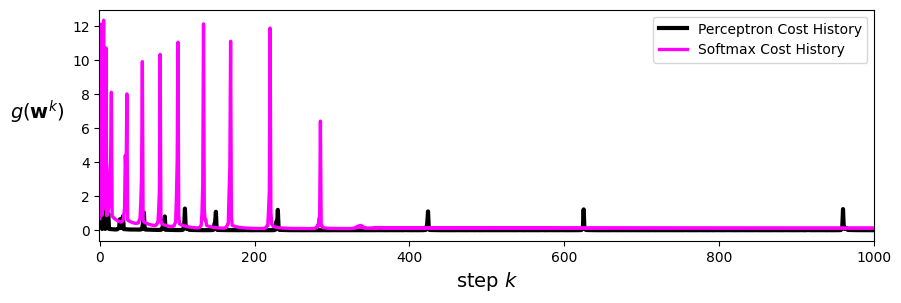

In [8]:
from MLRPlotting import static_plotter
# plotting the cost histories

# import custom plotting tools
static_plotter = static_plotter.Visualizer()
static_plotter.plot_cost_histories([cost_history_percep,cost_history_softmax],start=0,points=False,labels=[r'Perceptron Cost History',r'Softmax Cost History'])

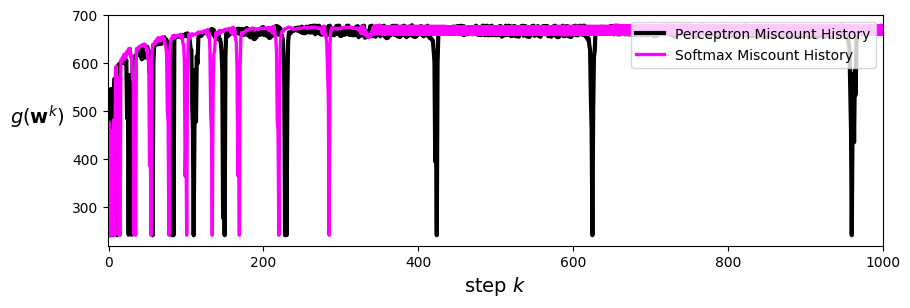

In [9]:
# plotting the miscount history
miscount_history_percep = [miscount(v,x,y) for v in weight_history_percep]	
miscount_history_softmax = [miscount(v,x,y) for v in weight_history_softmax]
static_plotter.plot_cost_histories([miscount_history_percep,miscount_history_softmax],start=0,points=False,labels=[r'Perceptron Miscount History',r'Softmax Miscount History'])

In [10]:
# The minimum misclassofied points for the perceptron and softmax models
print("Minimum misclassified points for perceptron: %d"%(np.min(miscount_history_percep)))
print("Minimum misclassified points for softmax: %d"%(np.min(miscount_history_softmax)))

Minimum misclassified points for perceptron: 241
Minimum misclassified points for softmax: 241


In [11]:
def miscount_malign(w, x, y):
    # count the number of misclassified malignant points
    preds = model(x, w)
    return np.sum((y == -1) & (preds > 0))

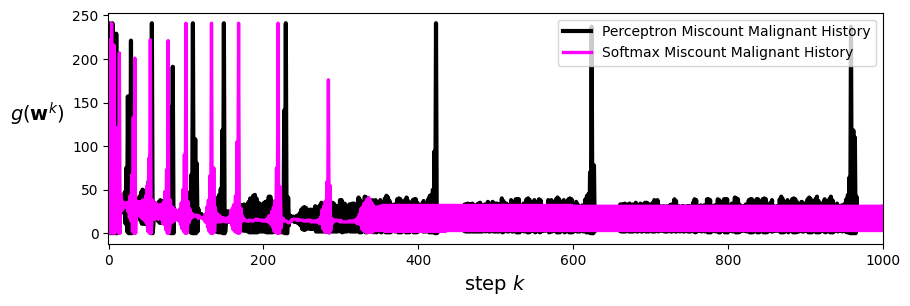

In [12]:
# misclassified malignant points
# plotting the miscount history
miscount_history_percep_malign = [miscount_malign(v,x,y) for v in weight_history_percep]	
miscount_history_softmax_malign = [miscount_malign(v,x,y) for v in weight_history_softmax]
static_plotter.plot_cost_histories([miscount_history_percep_malign,miscount_history_softmax_malign],start=0,points=False,labels=[r'Perceptron Miscount Malignant History',r'Softmax Miscount Malignant History'])

# 1.5

In [13]:
a=np.argwhere(y>0.9)
b=np.argwhere(y<-0.9)
yc=np.arange(699)
yc[a]=1
yc[b]=0

In [14]:
# define sigmoid function
def sigmoid(t):
    return 1/(1 + np.exp(-t))

# the convex cross-entropy cost function
lam = 2*10**(-3)
def cross_entropy(w):
    # compute sigmoid of model
    a = sigmoid(model(x,w))

    # compute cost of label 0 points
    ind = np.argwhere(yc == 0)
    cost = -np.sum(np.log(1 - a[:,ind]))

    # add cost on label 1 points
    ind = np.argwhere(yc==1)
    cost -= np.sum(np.log(a[:,ind]))

    # add regularizer
    cost += lam*np.sum(w[1:]**2)

    # compute cross-entropy
    return cost/float(np.size(yc))

In [15]:
# parameters for gradient descent
max_its = 1000
w = 0.1*np.random.randn(9,1)
alpha = 0.6
weight_history_cross_entropy, cost_history_cross_entropy = gradient_descent(cross_entropy,alpha,max_its,w)

We will consider a data point miscounted if the prediction is 1 and the model prediction is less than 0.5 and vice versa if the prediction is 0 and the model prediction is more than 0.5

In [16]:
# logistic regression miscount 
def miscount_logistic(w, x, y):
    # count the number of misclassified malignant points
    preds = model(x, w)
    return np.sum((preds > 0.5) != y)

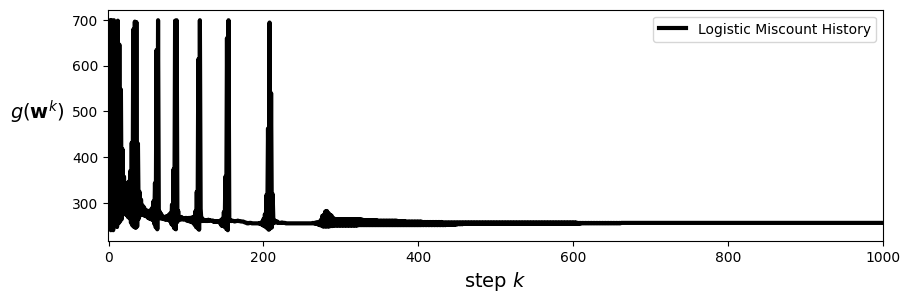

In [17]:
# plotting the miscount history
miscount_history_logistic = [miscount_logistic(v,x,y) for v in weight_history_cross_entropy]	
static_plotter.plot_cost_histories([miscount_history_logistic],start=0,points=False,labels=[r'Logistic Miscount History'])

We modify the miscount function by counting an error if the predicted proba is greater than 0.5 (default threshold) and the true value is 0 and vice versa, if the predicted proba is less than 0.5 (default threshold) and the true value is 1.